# BÀI THI GIỮA KỲ – Phân tích và Trực quan Dữ liệu
**Dữ liệu:** winequality-red.csv (UCI Machine Learning Repository)

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import squarify
sns.set_theme(style="whitegrid")

Phần 1: Xử lý dữ liệu (2 điểm) 
1. (1 điểm) Đọc file ‘winequality-red.csv’ từ đường dẫn và hiển thị 5 dòng đầu tiên. 
Gợi ý: sử dụng ‘pd.read_csv(...)’ và ‘df.head()’

In [41]:
import os
path = "winequality-red.csv"
if not os.path.exists(path):
    path = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(path, sep=";")
print("Kích thước dữ liệu:", df.shape)
df.head()

Kích thước dữ liệu: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


2. (1 điểm) Tính giá trị trung bình, nhỏ nhất, lớn nhất cho tất cả các cột số. 
Gợi ý: dùng ‘df.describe() hoặc chọn cụ thể mean, min, max. 

In [42]:
df.select_dtypes(include="number").agg(["mean", "min", "max"]).T

,mean,min,max
fixed acidity,8.319637,4.60000,15.90000
volatile acidity,0.527821,0.12000,1.58000
citric acid,0.270976,0.00000,1.00000
residual sugar,2.538806,0.90000,15.50000
chlorides,0.087467,0.01200,0.61100
free sulfur dioxide,15.874922,1.00000,72.00000
total sulfur dioxide,46.467792,6.00000,289.00000
density,0.996747,0.99007,1.00369
pH,3.311113,2.74000,4.01000
sulphates,0.658149,0.33000,2.00000


Phần 2: Trực quan hóa dữ liệu (6 điểm) 


3. (1 điểm) Vẽ biểu đồ histogram cho thuộc tính ‘alcohol’ với 20 bins. 
Gợi ý: dùng plt.hist(...) hoặc sns.histplot(...)

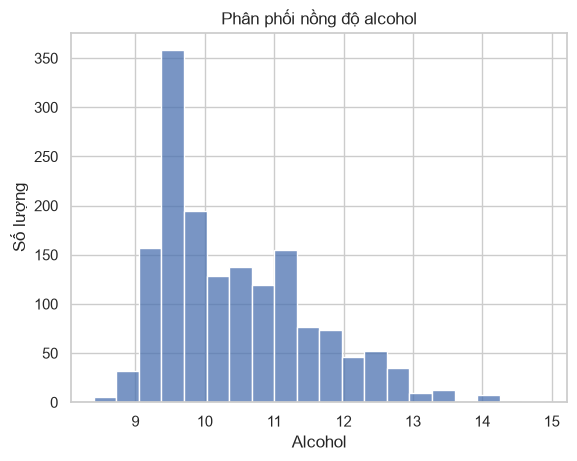

In [43]:
plt.Figure(figsize=(8,5))
sns.histplot(data=df, x="alcohol", bins=20, kde=False)
plt.title("Phân phối nồng độ alcohol")
plt.xlabel("Alcohol")
plt.ylabel("Số lượng")
plt.show()

4. (1 điểm) Vẽ biểu đồ boxplot so sánh ‘volatile acidity’ theo từng mức ‘quality’. 
Gợi ý: dùng sns.boxplot(x="quality", y="volatile acidity", data=df)

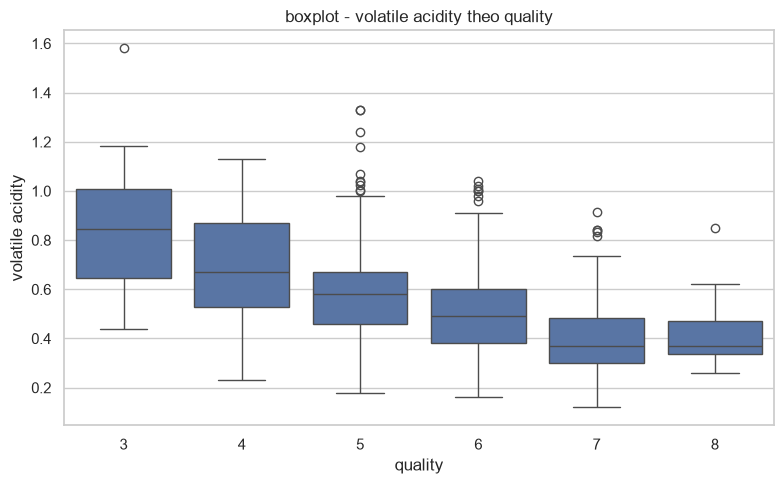

In [44]:
plt.figure(figsize = (8,5))
sns.boxplot(x='quality',y='volatile acidity',data=df)
plt.title('boxplot - volatile acidity theo quality')
plt.tight_layout()
plt.show()

5. (1 điểm) Vẽ scatter plot giữa ‘alcohol’ và ‘density’, màu theo ‘quality’. 
Gợi ý: sns.scatterplot(x="alcohol", y="density", hue="quality", data=df)`

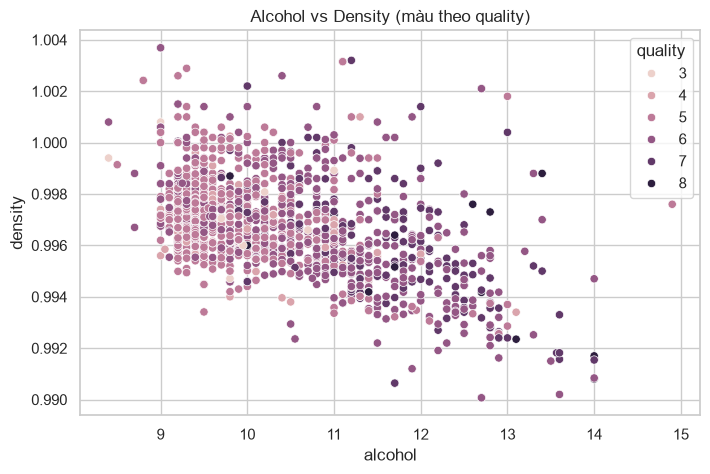

In [45]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="alcohol", y="density", hue="quality", data=df)
plt.title('Alcohol vs Density (màu theo quality)')
plt.show()

6. (1 điểm) Vẽ Treemap thể hiện tổng lượng ‘alcohol’ theo từng mức ‘quality’. 
Gợi ý: nhóm theo ‘quality’ rồi dùng ‘squarify.plot(...)’

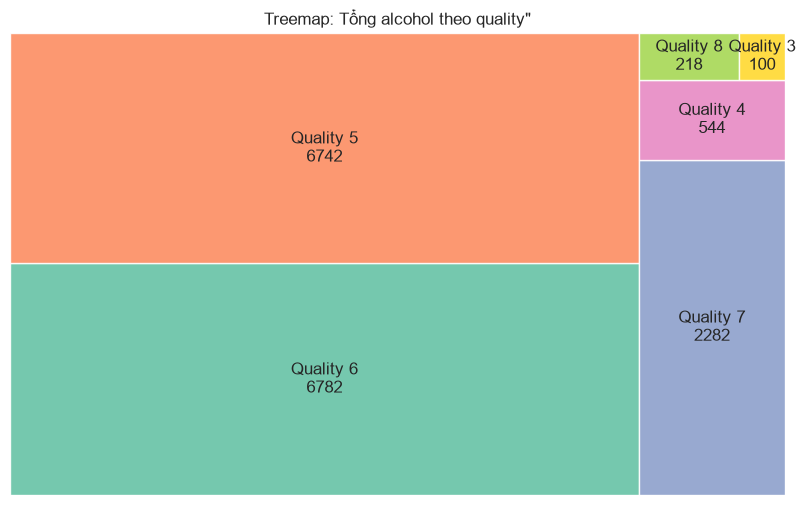

In [46]:
alc_sum = df.groupby('quality')['alcohol'].sum().sort_values(ascending=False)
labels = [f"Quality {q}\n{v:.0f}" for q, v in alc_sum.items()]
sizes = alc_sum.values
plt.figure(figsize=(10,6))
squarify.plot(sizes=alc_sum.values, label=labels,
              color=sns.color_palette("Set2", len(alc_sum)), alpha=0.9)
plt.title('Treemap: Tổng alcohol theo quality"')
plt.axis("off")
plt.show()

7. (1 điểm) Vẽ biểu đồ Pie thể hiện tỷ lệ số dòng tương ứng với từng mức ‘quality’. 
Gợi ý: ‘df["quality"].value_counts()’ và ‘plt.pie(...)’ 

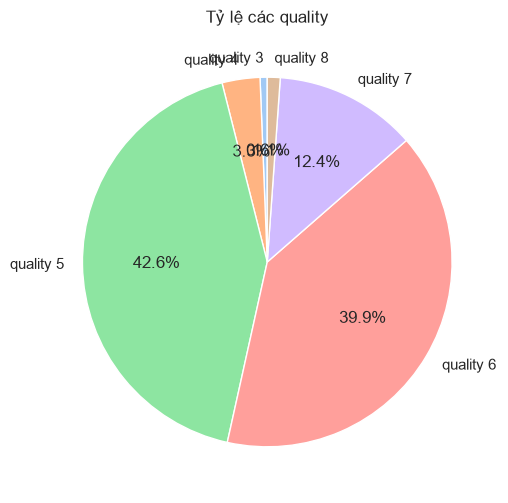

In [47]:
count = df['quality'].value_counts().sort_index()
plt.figure(figsize=(6,6))
plt.pie(count.values,labels=[f'quality {q}' for q in count.index],
        autopct='%1.1f%%',startangle=90,colors=sns.color_palette('pastel'))
plt.title('Tỷ lệ các quality')
plt.show()

8. (1 điểm) Vẽ biểu đồ cột ngang biểu diễn tổng ‘sulphates’ theo từng mức ‘quality’. 
Gợi ý: ‘groupby("quality")["sulphates"].sum().plot(kind="barh")’

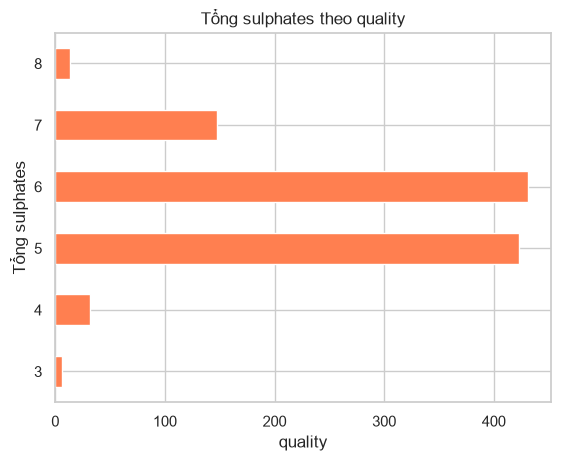

In [48]:
plt.Figure(figsize=(8,5))
df.groupby('quality')['sulphates'].sum().plot(kind='barh',color='coral')
plt.title('Tổng sulphates theo quality')
plt.xlabel('quality')
plt.ylabel('Tổng sulphates')
plt.show()

Phần 3: Nhận xét kết quả (2 điểm)

9. (1 điểm) Theo boxplot, chất lượng rượu nào có độ acid bay hơi trung bình cao nhất?

In [49]:
# Kiểm chứng bằng số liệu: trung bình volatile acidity theo quality
df.groupby("quality")["volatile acidity"].mean().round(3)

quality
3    0.885
4    0.694
5    0.577
6    0.497
7    0.404
8    0.423
Name: volatile acidity, dtype: float64

**Trả lời:** Rượu **chất lượng 3** có độ acid bay hơi trung bình cao nhất (**0.885** g/dm³).

Xu hướng chung: quality tăng thì volatile acidity giảm: 0.694 (quality 4), 0.577 (5), 0.497 (6), 0.404 (7); quality 8 là 0.423 (nhỉnh hơn quality 7 một chút). Acid bay hơi cao tạo mùi giấm khó chịu nên làm giảm chất lượng rượu.

10. (1 điểm) Theo scatter plot, rượu chất lượng cao có xu hướng chứa nhiều hay ít 
alcohol? Vì sao? 

In [50]:
# Kiểm chứng: trung bình alcohol theo quality và tương quan với quality
print(df.groupby("quality")["alcohol"].mean().round(2))
print("Tương quan alcohol - quality:", round(df["alcohol"].corr(df["quality"]), 3))
print("Tương quan alcohol - density:", round(df["alcohol"].corr(df["density"]), 3))

quality
3     9.96
4    10.27
5     9.90
6    10.63
7    11.47
8    12.09
Name: alcohol, dtype: float64
Tương quan alcohol - quality: 0.476
Tương quan alcohol - density: -0.496


**Trả lời:** Rượu chất lượng cao có xu hướng chứa **nhiều alcohol hơn**. Các điểm màu đậm (quality 7–8) tập trung ở vùng alcohol cao (~11–13%), còn quality 5 tập trung ở vùng ~9–10%.

Số liệu: alcohol trung bình theo quality là 9.90 (quality 5), 10.63 (6), 11.47 (7), 12.09 (8); hệ số tương quan alcohol–quality = **+0.476**. (Quality 3 và 4 có rất ít mẫu nên trung bình dao động: 9.96 và 10.27.)

**Vì sao:** (1) Rượu có alcohol cao thường được làm từ nho chín hơn, nhiều đường, cho hương vị đậm đà, cân bằng hơn nên được chấm điểm cao. (2) Trên scatter plot, alcohol tăng thì density giảm (tương quan alcohol–density = **-0.496**) vì ethanol nhẹ hơn nước, nên rượu chất lượng cao cũng thường có density thấp. (Lưu ý: đây là tương quan, chưa chứng minh nhân quả.)